## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings('ignore')

## 2. Load the dataset

In [2]:
print("Loading Walmart dataset from multiple CSV files...")

try:
    # Load the main data files
    features_df = pd.read_csv('features.csv')
    stores_df = pd.read_csv('stores.csv')
    train_df = pd.read_csv('train.csv')
    
    print("✅ All CSV files loaded successfully!")
    print(f"features.csv shape: {features_df.shape}")
    print(f"stores.csv shape: {stores_df.shape}")
    print(f"train.csv shape: {train_df.shape}")
    
    # Merge all datasets
    # First merge train with features
    df = pd.merge(train_df, features_df, on=['Store', 'Date', 'IsHoliday'], how='left')


    # Then merge with stores information
    df = pd.merge(df, stores_df, on='Store', how='left')
    
    print(f"✅ Merged dataset shape: {df.shape}")
    
except FileNotFoundError as e:
    print(f"❌ Error loading files: {e}")
    print("Please make sure you have these files in your directory:")
    print("1. features.csv")
    print("2. stores.csv") 
    print("3. train.csv")
    exit()


    

Loading Walmart dataset from multiple CSV files...
✅ All CSV files loaded successfully!
features.csv shape: (8190, 12)
stores.csv shape: (45, 3)
train.csv shape: (421570, 5)
✅ Merged dataset shape: (421570, 16)


## 3. Data exploration

In [4]:
print("\n First 5 rows of merged data:")
print(df.head())
print("\n Dataset info:")
print(df.info())
print("\n Missing values:")
print(df.isnull().sum())


 First 5 rows of merged data:
   Store  Dept        Date  Weekly_Sales  IsHoliday  Temperature  Fuel_Price  \
0      1     1  2010-02-05      24924.50      False        42.31       2.572   
1      1     1  2010-02-12      46039.49       True        38.51       2.548   
2      1     1  2010-02-19      41595.55      False        39.93       2.514   
3      1     1  2010-02-26      19403.54      False        46.63       2.561   
4      1     1  2010-03-05      21827.90      False        46.50       2.625   

   MarkDown1  MarkDown2  MarkDown3  MarkDown4  MarkDown5         CPI  \
0        NaN        NaN        NaN        NaN        NaN  211.096358   
1        NaN        NaN        NaN        NaN        NaN  211.242170   
2        NaN        NaN        NaN        NaN        NaN  211.289143   
3        NaN        NaN        NaN        NaN        NaN  211.319643   
4        NaN        NaN        NaN        NaN        NaN  211.350143   

   Unemployment Type    Size  
0         8.106    A  15

## 4. Data cleaning and preprocessing

In [5]:
# Convert date column
df['Date'] = pd.to_datetime(df['Date'])

#Handle missing values - fill with mean or appropriate values
numeric_cols = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Size']
for col in numeric_cols:
    if col in df.columns:
        df[col].fillna(df[col].mean(), inplace=True)

# Convert IsHoliday to numeric (1 for True, 0 for False)
df['Holiday_Flag'] = df['IsHoliday'].astype(int)

# Create additional time-based features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week
df['Day_of_week'] = df['Date'].dt.dayofweek
df['Day_of_year'] = df['Date'].dt.dayofyear

## 5. Visualize the data

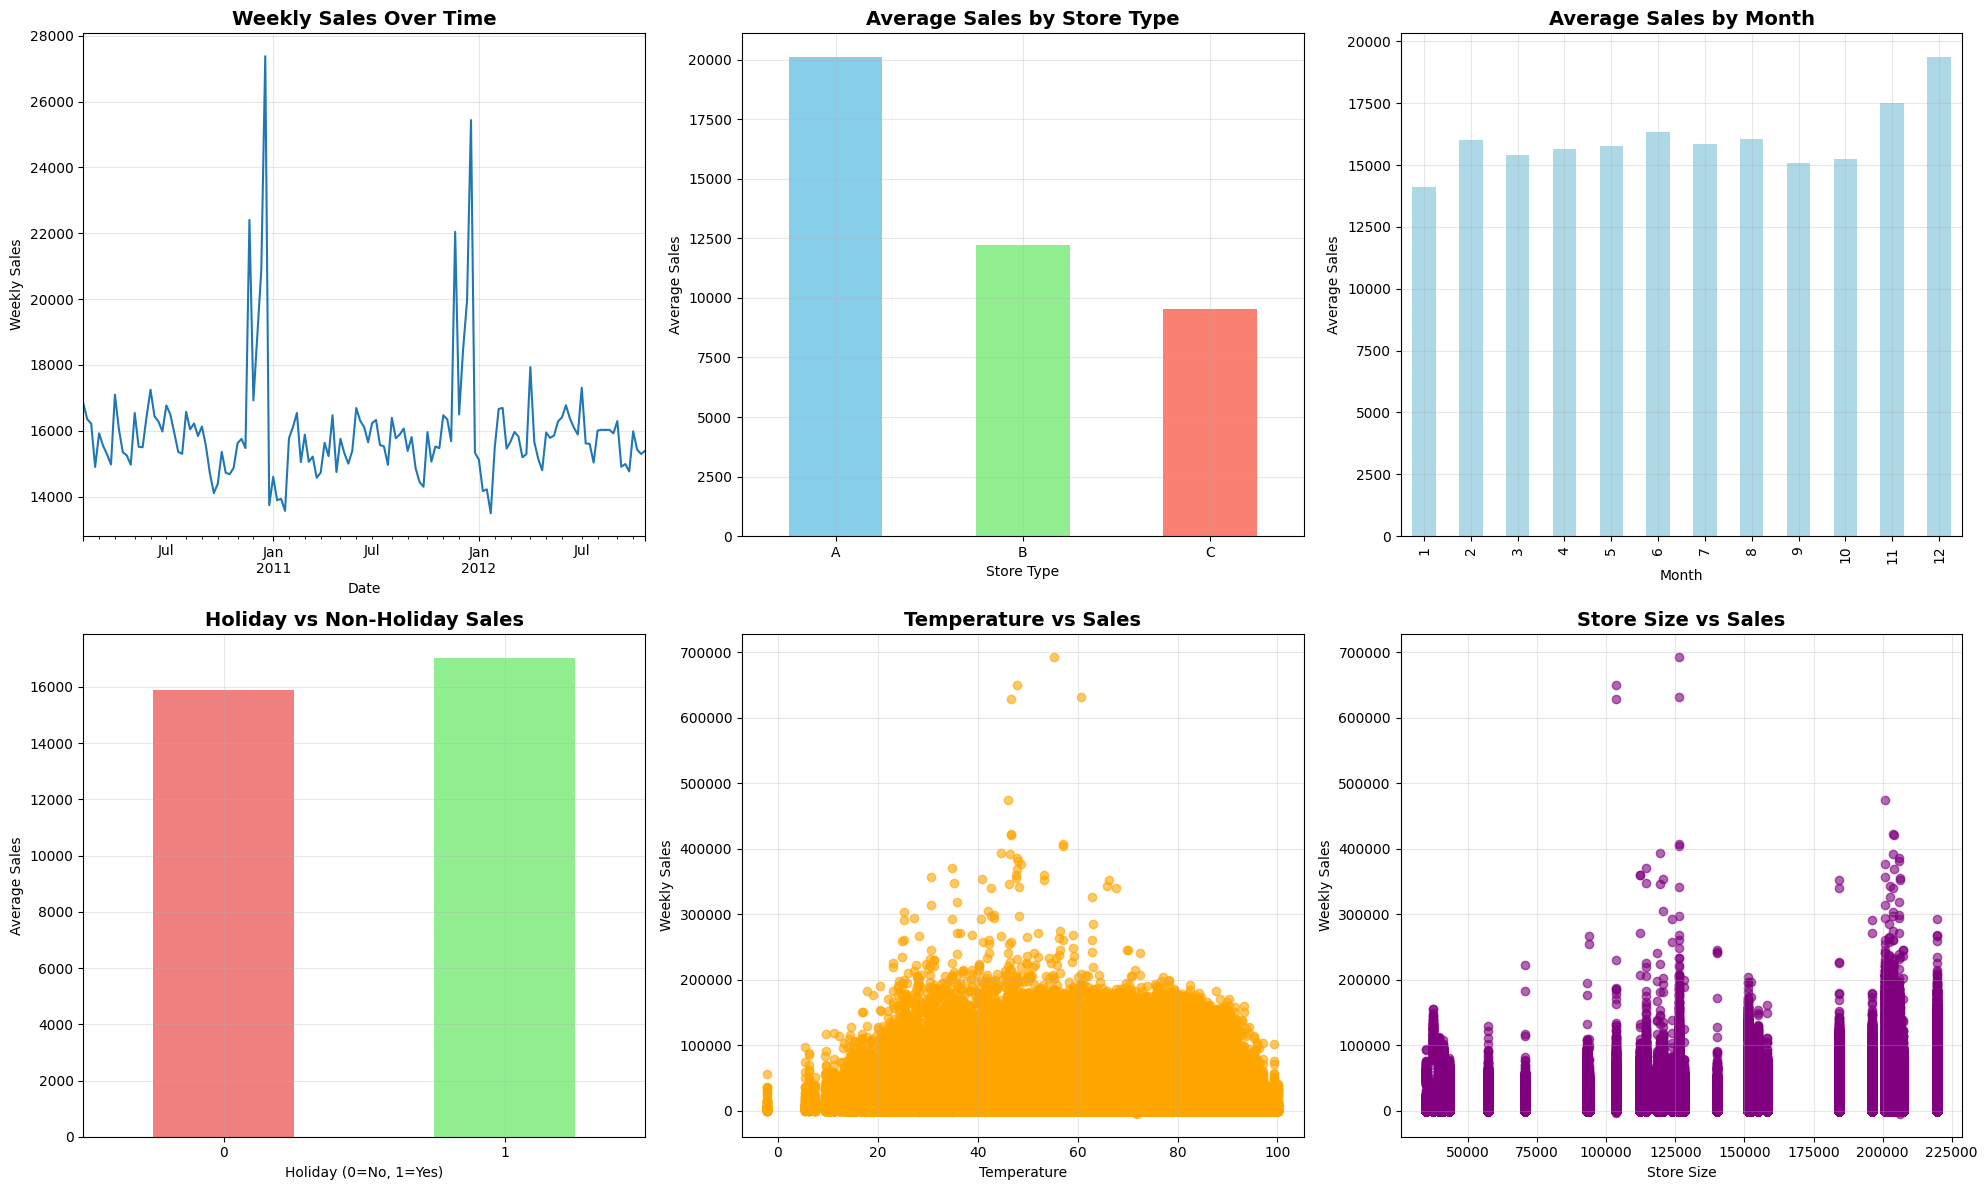

In [7]:

plt.figure(figsize=(20, 12))

# 1. Weekly Sales over time
plt.subplot(2, 3, 1)
df.groupby('Date')['Weekly_Sales'].mean().plot()
plt.title('Weekly Sales Over Time', fontsize=14, fontweight='bold')  
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 2. Sales by store type
plt.subplot(2, 3, 2)
if 'Type' in df.columns:
    df.groupby('Type')['Weekly_Sales'].mean().plot(kind='bar', color=['skyblue', 'lightgreen', 'salmon'])
    plt.title('Average Sales by Store Type', fontsize=14, fontweight='bold') 
    plt.xlabel('Store Type')
    plt.ylabel('Average Sales')
    plt.xticks(rotation=0)
    plt.grid(True, alpha=0.3)

# 3. Sales by month
plt.subplot(2, 3, 3)
df.groupby('Month')['Weekly_Sales'].mean().plot(kind='bar', color='lightblue')
plt.title('Average Sales by Month', fontsize=14, fontweight='bold')  
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.grid(True, alpha=0.3)

# 4. Holiday vs Non-Holiday sales
plt.subplot(2, 3, 4)
df.groupby('Holiday_Flag')['Weekly_Sales'].mean().plot(kind='bar', color=['lightcoral', 'lightgreen'])
plt.title('Holiday vs Non-Holiday Sales', fontsize=14, fontweight='bold')  
plt.xlabel('Holiday (0=No, 1=Yes)')
plt.ylabel('Average Sales')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3)

# 5. Temperature vs Sales
plt.subplot(2, 3, 5)
plt.scatter(df['Temperature'], df['Weekly_Sales'], alpha=0.6, color='orange')
plt.title('Temperature vs Sales', fontsize=14, fontweight='bold')  
plt.xlabel('Temperature')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

# 6. Store size vs Sales
plt.subplot(2, 3, 6)
plt.scatter(df['Size'], df['Weekly_Sales'], alpha=0.6, color='purple')
plt.title('Store Size vs Sales', fontsize=14, fontweight='bold')  
plt.xlabel('Store Size')
plt.ylabel('Weekly Sales')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Create lag features for time series analysis

In [9]:
def create_lag_features(group, lags=[1, 2, 3, 4, 5, 52]):
    """Create lag features for each store and department"""
    for lag in lags:
        group[f'Sales_lag_{lag}'] = group['Weekly_Sales'].shift(lag)
    return group

# Apply lag features by store and department
df = df.groupby(['Store', 'Dept']).apply(create_lag_features).reset_index(drop=True)

# Remove rows with NaN values from lag features
df_clean = df.dropna().copy()
print(f" Clean dataset shape after lag features: {df_clean.shape}")


 Clean dataset shape after lag features: (95214, 28)


## 7. Prepare features and target variable

In [10]:
features = [
    'Store', 'Dept', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 
    'CPI', 'Unemployment', 'Size', 'Year', 'Month', 'Week', 
    'Day_of_week', 'Day_of_year'
]

# Add store type if available
if 'Type' in df_clean.columns:
    # Convert store type to numeric (A=0, B=1, C=2)
    df_clean['Type_numeric'] = df_clean['Type'].map({'A': 0, 'B': 1, 'C': 2})
    features.append('Type_numeric')

# Add lag features
features += [col for col in df_clean.columns if 'Sales_lag_' in col]

X = df_clean[features]
y = df_clean['Weekly_Sales']

print(f"📋 Number of features: {len(features)}")
print(f"🎯 Target variable: Weekly_Sales")

📋 Number of features: 20
🎯 Target variable: Weekly_Sales


## 8. Split the data (time-based split)

In [11]:
# Sort by date to ensure proper time-based split
df_clean = df_clean.sort_values('Date')
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"\n📊 Data split:")
print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")


📊 Data split:
Training set: (76171, 20)
Test set: (19043, 20)


## 9. Scale the features

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 10. Train and compare multiple models

In [14]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42, max_depth=5)
}

print("\n" + "="*60)
print("🤖 TRAINING MACHINE LEARNING MODELS")
print("="*60)

results = {}
for name, model in models.items():
    print(f"\n🔧 Training {name}...")
    model.fit(X_train_scaled, y_train)


# Make predictions
    y_pred = model.predict(X_test_scaled)
    
    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results[name] = {
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'model': model,
        'predictions': y_pred
    }
    
    print(f"   ✅ MAE: ${mae:,.2f}")
    print(f"   ✅ RMSE: ${rmse:,.2f}")
    print(f"   ✅ R²: {r2:.4f}")



🤖 TRAINING MACHINE LEARNING MODELS

🔧 Training Linear Regression...
   ✅ MAE: $1,760.99
   ✅ RMSE: $3,630.70
   ✅ R²: 0.9710

🔧 Training Random Forest...
   ✅ MAE: $1,431.00
   ✅ RMSE: $2,992.06
   ✅ R²: 0.9803

🔧 Training Gradient Boosting...
   ✅ MAE: $1,409.44
   ✅ RMSE: $2,904.19
   ✅ R²: 0.9814


## 11. Compare model results

In [15]:
print("\n" + "="*60)
print("🏆 MODEL COMPARISON RESULTS")
print("="*60)

results_df = pd.DataFrame([
    {
        'Model': name,
        'MAE': f"${metrics['MAE']:,.2f}",
        'RMSE': f"${metrics['RMSE']:,.2f}", 
        'R2': f"{metrics['R2']:.4f}",
        'R2_Score': metrics['R2']
    }
    for name, metrics in results.items()
]).sort_values('R2_Score', ascending=False)

print(results_df.drop('R2_Score', axis=1))


🏆 MODEL COMPARISON RESULTS
               Model        MAE       RMSE      R2
2  Gradient Boosting  $1,409.44  $2,904.19  0.9814
1      Random Forest  $1,431.00  $2,992.06  0.9803
0  Linear Regression  $1,760.99  $3,630.70  0.9710


## 12. Visualize predictions

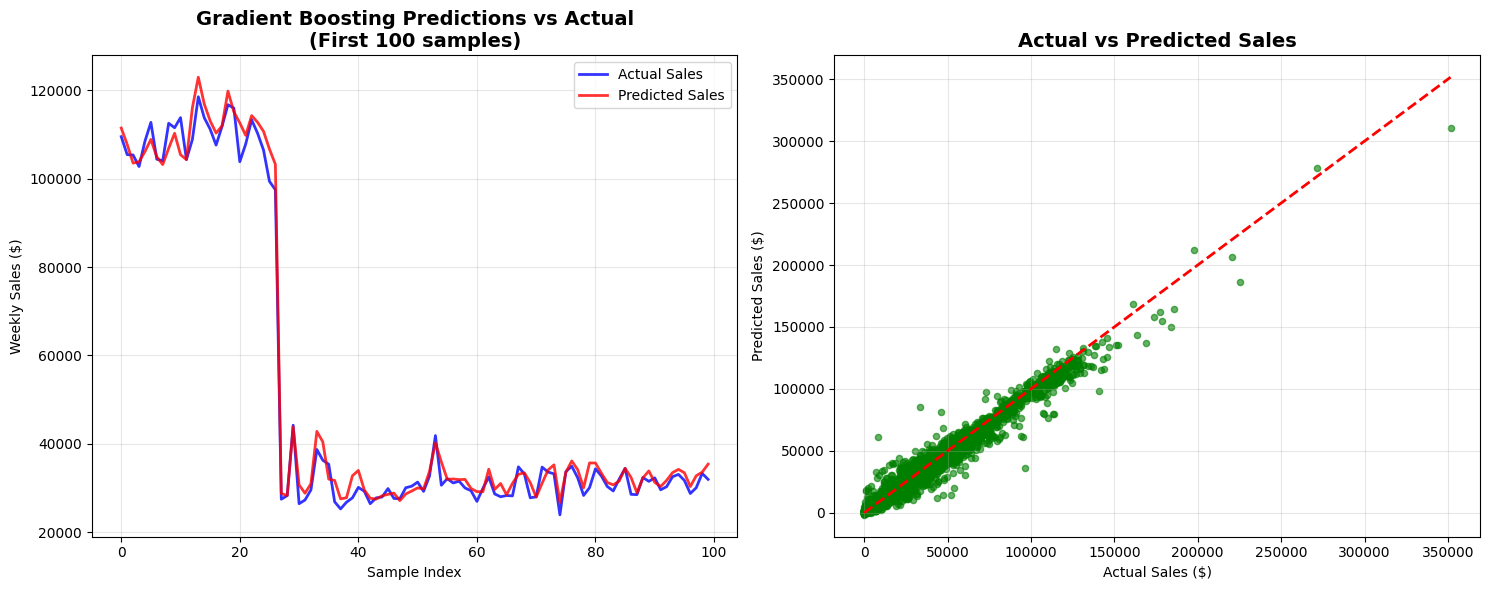

In [16]:
best_model_name = results_df.iloc[0]['Model']
best_predictions = results[best_model_name]['predictions']

plt.figure(figsize=(15, 6))

# Time series comparison (first 100 samples)
plt.subplot(1, 2, 1)
plt.plot(y_test.values[:100], label='Actual Sales', linewidth=2, alpha=0.8, color='blue')
plt.plot(best_predictions[:100], label='Predicted Sales', linewidth=2, alpha=0.8, color='red')
plt.title(f'{best_model_name} Predictions vs Actual\n(First 100 samples)', fontsize=14, fontweight='bold')
plt.xlabel('Sample Index')
plt.ylabel('Weekly Sales ($)')
plt.legend()
plt.grid(True, alpha=0.3)

# Scatter plot of actual vs predicted
plt.subplot(1, 2, 2)
plt.scatter(y_test, best_predictions, alpha=0.6, color='green', s=20)
max_val = max(y_test.max(), best_predictions.max())
plt.plot([0, max_val], [0, max_val], 'r--', linewidth=2)
plt.title('Actual vs Predicted Sales', fontsize=14, fontweight='bold')
plt.xlabel('Actual Sales ($)')
plt.ylabel('Predicted Sales ($)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 13. Feature importance analysis

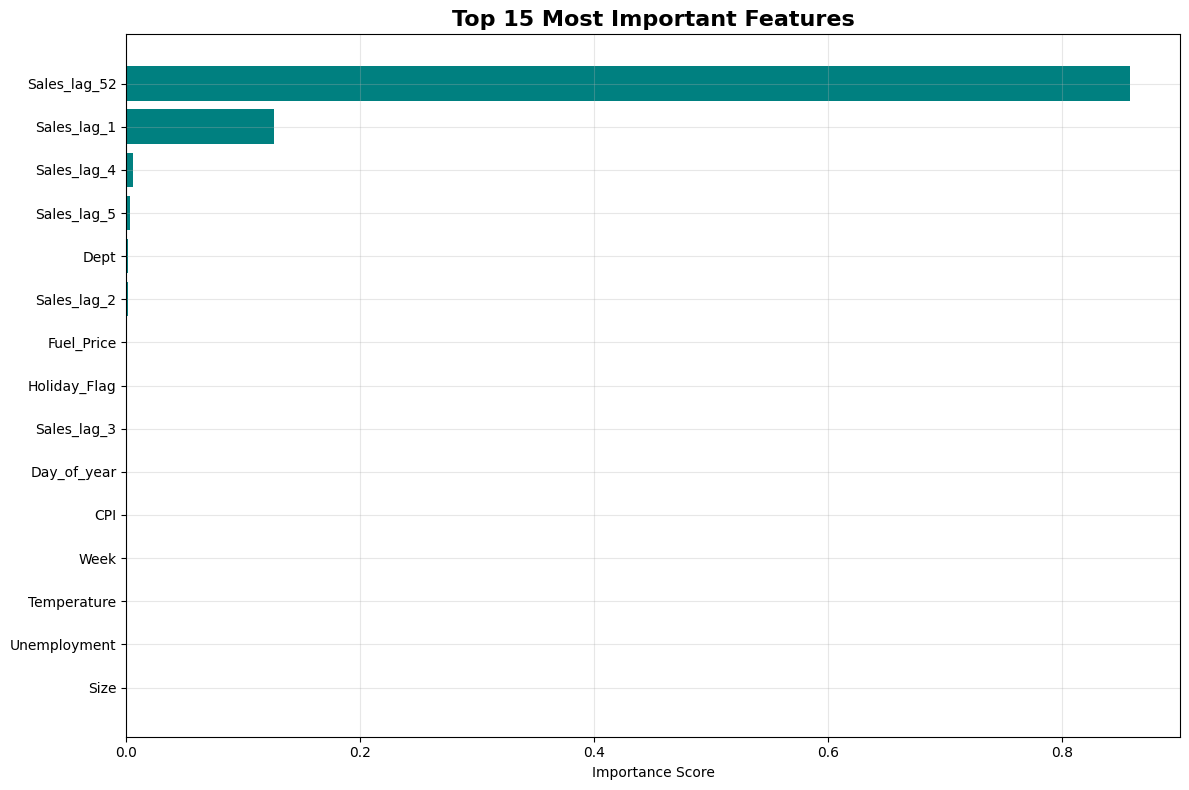


📊 Top 10 most important features:
         Feature  Importance
19  Sales_lag_52    0.857735
14   Sales_lag_1    0.125892
17   Sales_lag_4    0.005678
18   Sales_lag_5    0.003274
1           Dept    0.001286
15   Sales_lag_2    0.001110
4     Fuel_Price    0.000913
2   Holiday_Flag    0.000868
16   Sales_lag_3    0.000545
12   Day_of_year    0.000542


In [17]:
best_model = results[best_model_name]['model']

if hasattr(best_model, 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'Feature': features,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)
    
    plt.figure(figsize=(12, 8))
    plt.barh(feature_importance['Feature'][:15], feature_importance['Importance'][:15], color='teal')
    plt.title('Top 15 Most Important Features', fontsize=16, fontweight='bold')
    plt.xlabel('Importance Score')
    plt.gca().invert_yaxis()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("\n📊 Top 10 most important features:")
    print(feature_importance.head(10)[['Feature', 'Importance']])


## 14. Final results and model saving

In [18]:
print("\n" + "="*60)
print("🎯 FINAL RESULTS")
print("="*60)
print(f"🏆 Best Model: {best_model_name}")
print(f"📊 R² Score: {results[best_model_name]['R2']:.4f}")
print(f"💰 MAE: ${results[best_model_name]['MAE']:,.2f}")
print(f"📈 RMSE: ${results[best_model_name]['RMSE']:,.2f}")

# Save the best model
import joblib
joblib.dump(best_model, 'walmart_sales_forecast_model.pkl')
joblib.dump(scaler, 'walmart_scaler.pkl')
print(f"\n💾 Model saved as 'walmart_sales_forecast_model.pkl'")
print(f"💾 Scaler saved as 'walmart_scaler.pkl'")

print(f"\n✅ Walmart Sales Forecasting Task Completed Successfully!")
print("📈 The model is ready to predict future sales!")


🎯 FINAL RESULTS
🏆 Best Model: Gradient Boosting
📊 R² Score: 0.9814
💰 MAE: $1,409.44
📈 RMSE: $2,904.19

💾 Model saved as 'walmart_sales_forecast_model.pkl'
💾 Scaler saved as 'walmart_scaler.pkl'

✅ Walmart Sales Forecasting Task Completed Successfully!
📈 The model is ready to predict future sales!


# Thank You